<a href="https://colab.research.google.com/github/azelepou/IntroMachineLearning/blob/main/ML_HW4_AnatolyZelepouga_801236217.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problem 1: Cancer classification
Training rows: 455
Evaluation rows: 114
Positive class: malignant
              model  accuracy  precision   recall       f1
         SVM-linear  0.964912        1.0 0.904762 0.950000
           SVM-poly  0.885965        1.0 0.690476 0.816901
            SVM-rbf  0.973684        1.0 0.928571 0.962963
Logistic regression  0.982456        1.0 0.952381 0.975610
Best SVM kernel by accuracy: rbf


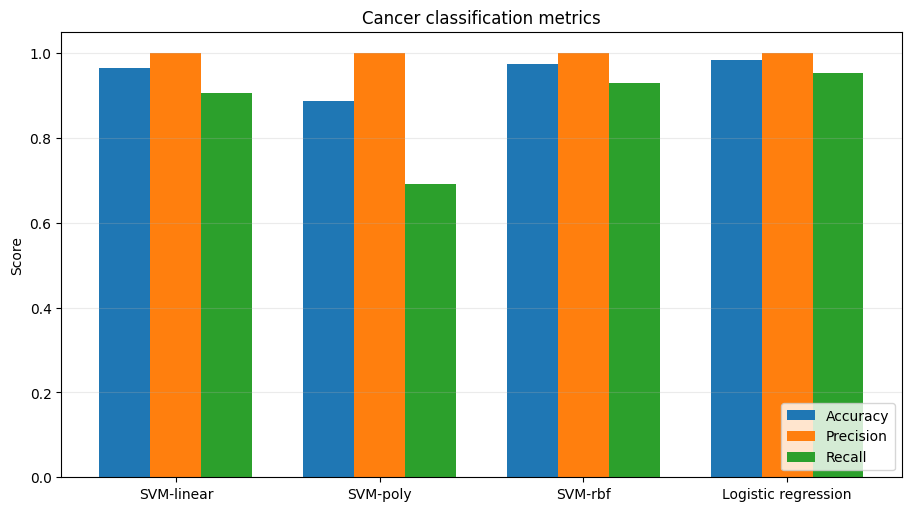

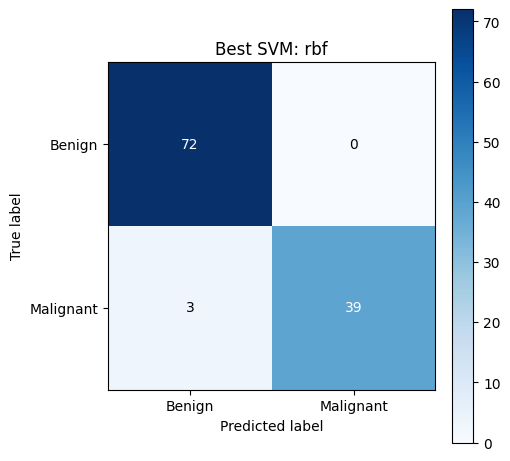


Problem 2: Housing regression
Training rows: 436
Evaluation rows: 109
Price unit: millions of the dataset's original price units
                        model  rmse_millions  mae_millions        r2
                   SVR-linear       1.400300      1.014510  0.612066
                     SVR-poly       2.552887      1.660706 -0.289374
                      SVR-rbf       1.439606      1.082145  0.589982
Regularized linear regression       1.342156      0.979147  0.643613
Best SVR kernel by RMSE: linear


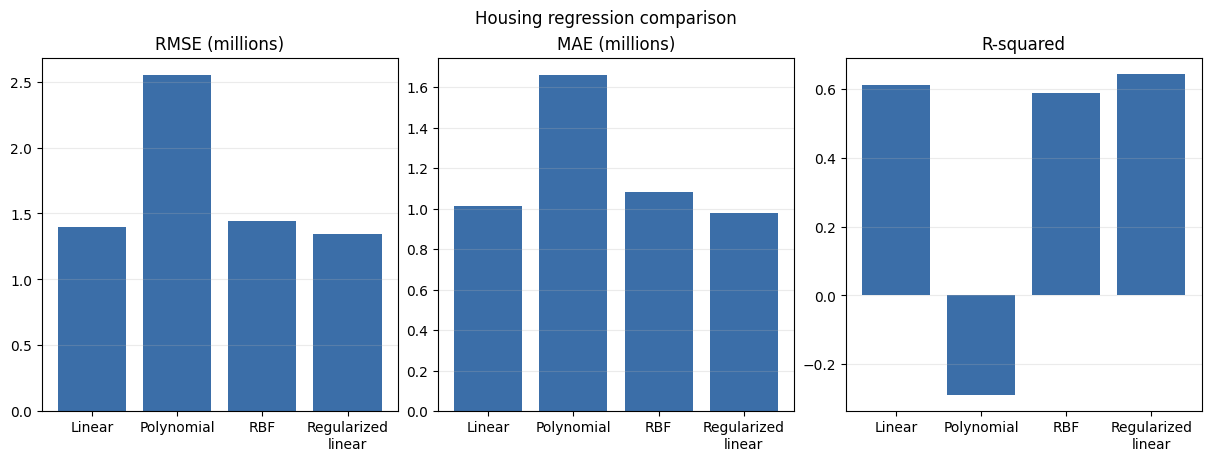

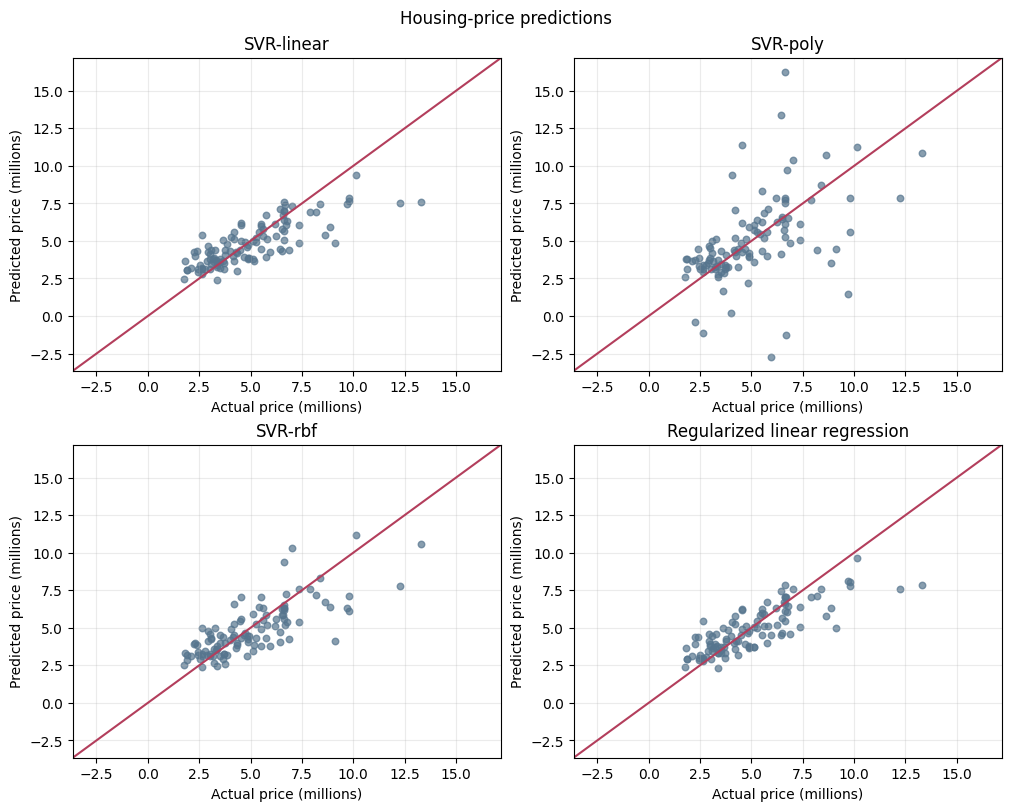


Finished. The four charts are also saved as PNG files.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, mean_squared_error, mean_absolute_error, r2_score
)

random_seed = 42
kernels = ["linear", "poly", "rbf"]


# Problem 1: Read and prepare the cancer data.
cancer = pd.read_csv("Cancer.csv")

labels = []
for value in cancer["diagnosis"]:
    diagnosis = str(value).strip()

    if diagnosis == "B":
        labels.append(0)
    elif diagnosis == "M":
        labels.append(1)
    else:
        raise ValueError("Cancer diagnosis must be B or M.")

cancer_inputs = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)

X_cancer = cancer_inputs.to_numpy(dtype=float)
y_cancer = np.array(labels)

if not np.isfinite(X_cancer).all():
    raise ValueError("The cancer inputs contain invalid values.")

# Keep 20% for evaluation and preserve the class proportions.
Xc_train, Xc_eval, yc_train, yc_eval = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.20,
    random_state=random_seed,
    stratify=y_cancer
)

# Learn the scaling from the training data only.
cancer_scaler = StandardScaler()
Xc_train = cancer_scaler.fit_transform(Xc_train)
Xc_eval = cancer_scaler.transform(Xc_eval)

# Train an SVM for each kernel.
cancer_names = []
cancer_predictions = []

for kernel in kernels:
    model = SVC(
        kernel=kernel,
        C=1.0,
        degree=3,
        gamma="scale"
    )

    model.fit(Xc_train, yc_train)
    predicted = model.predict(Xc_eval)

    cancer_names.append("SVM-" + kernel)
    cancer_predictions.append(predicted)

# Fit a logistic-regression reference on the same split.
train_design = np.column_stack(
    (np.ones(len(Xc_train)), Xc_train)
)
eval_design = np.column_stack(
    (np.ones(len(Xc_eval)), Xc_eval)
)

theta = np.zeros(train_design.shape[1])

for iteration in range(2000):
    scores = train_design.dot(theta)
    scores = np.clip(scores, -40, 40)

    probabilities = 1.0 / (1.0 + np.exp(-scores))
    errors = probabilities - yc_train

    gradient = train_design.T.dot(errors) / len(yc_train)
    theta = theta - 0.05 * gradient

scores = eval_design.dot(theta)
scores = np.clip(scores, -40, 40)
probabilities = 1.0 / (1.0 + np.exp(-scores))

logistic_predictions = []

for probability in probabilities:
    if probability >= 0.50:
        logistic_predictions.append(1)
    else:
        logistic_predictions.append(0)

cancer_names.append("Logistic regression")
cancer_predictions.append(np.array(logistic_predictions))

# Calculate the evaluation scores for each model.
cancer_rows = []

for i in range(len(cancer_names)):
    predicted = cancer_predictions[i]

    accuracy = accuracy_score(yc_eval, predicted)
    precision = precision_score(
        yc_eval, predicted, zero_division=0
    )
    recall = recall_score(
        yc_eval, predicted, zero_division=0
    )
    f1 = f1_score(
        yc_eval, predicted, zero_division=0
    )

    cancer_rows.append([
        cancer_names[i],
        accuracy,
        precision,
        recall,
        f1
    ])

cancer_results = pd.DataFrame(
    cancer_rows,
    columns=["model", "accuracy", "precision", "recall", "f1"]
)

print("Problem 1: Cancer classification")
print("Training rows:", len(yc_train))
print("Evaluation rows:", len(yc_eval))
print("Positive class: malignant")
print(cancer_results.round(6).to_string(index=False))

# Select the highest-accuracy SVM, excluding the logistic reference.
best_svm_index = 0

for i in range(1, len(kernels)):
    if cancer_rows[i][1] > cancer_rows[best_svm_index][1]:
        best_svm_index = i

print("Best SVM kernel by accuracy:", kernels[best_svm_index])

# Compare accuracy, precision, and recall.
positions = np.arange(len(cancer_names))
width = 0.25

fig, ax = plt.subplots(
    figsize=(9, 5),
    constrained_layout=True
)

ax.bar(
    positions - width,
    cancer_results["accuracy"],
    width,
    label="Accuracy"
)
ax.bar(
    positions,
    cancer_results["precision"],
    width,
    label="Precision"
)
ax.bar(
    positions + width,
    cancer_results["recall"],
    width,
    label="Recall"
)

ax.set_xticks(positions)
ax.set_xticklabels([
    "SVM-linear", "SVM-poly", "SVM-rbf", "Logistic regression"
])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Cancer classification metrics")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.25)

fig.savefig("classification_kernel_comparison.png", dpi=220)
plt.show()
plt.close(fig)

# Show the best SVM's correct and incorrect classifications.
matrix = confusion_matrix(
    yc_eval,
    cancer_predictions[best_svm_index],
    labels=[0, 1]
)

fig, ax = plt.subplots(
    figsize=(5, 4.5),
    constrained_layout=True
)

image = ax.imshow(matrix, cmap="Blues")
fig.colorbar(image, ax=ax)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Benign", "Malignant"])
ax.set_yticklabels(["Benign", "Malignant"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Best SVM: " + kernels[best_svm_index])

for row in range(2):
    for column in range(2):
        if matrix[row, column] > matrix.max() / 2:
            text_color = "white"
        else:
            text_color = "black"

        ax.text(
            column,
            row,
            str(matrix[row, column]),
            ha="center",
            va="center",
            color=text_color
        )

fig.savefig("best_svm_confusion_matrix.png", dpi=220)
plt.show()
plt.close(fig)


# Problem 2: Read the housing data and select the required inputs.
housing = pd.read_csv("Housing.csv")

housing_columns = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "parking",
    "prefarea"
]

binary_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

housing_inputs = housing[housing_columns].copy()

# Convert each yes/no input into 1 or 0.
for column in binary_columns:
    encoded_values = []

    for value in housing_inputs[column]:
        answer = str(value).strip().lower()

        if answer == "yes":
            encoded_values.append(1)
        elif answer == "no":
            encoded_values.append(0)
        else:
            raise ValueError("Expected yes or no in " + column)

    housing_inputs[column] = encoded_values

X_housing = housing_inputs.to_numpy(dtype=float)

# Express prices in millions, using the same units as the earlier code.
y_housing = housing["price"].to_numpy(dtype=float) / 1_000_000.0

if not np.isfinite(X_housing).all():
    raise ValueError("The housing inputs contain invalid values.")

if not np.isfinite(y_housing).all():
    raise ValueError("The housing prices contain invalid values.")

# Use the same evaluation rows for all housing models.
Xh_train, Xh_eval, yh_train, yh_eval = train_test_split(
    X_housing,
    y_housing,
    test_size=0.20,
    random_state=random_seed
)

housing_scaler = StandardScaler()
Xh_train = housing_scaler.fit_transform(Xh_train)
Xh_eval = housing_scaler.transform(Xh_eval)

# Train an SVR model for each kernel.
housing_names = []
housing_predictions = []

for kernel in kernels:
    model = SVR(
        kernel=kernel,
        C=100.0,
        epsilon=0.05,
        degree=3,
        gamma="scale"
    )

    model.fit(Xh_train, yh_train)
    predicted = model.predict(Xh_eval)

    housing_names.append("SVR-" + kernel)
    housing_predictions.append(predicted)

# Fit a regularized-linear reference on the same split.
ridge = Ridge(alpha=1.0)
ridge.fit(Xh_train, yh_train)
ridge_predictions = ridge.predict(Xh_eval)

housing_names.append("Regularized linear regression")
housing_predictions.append(ridge_predictions)

# Calculate prediction errors and R-squared.
housing_rows = []

for i in range(len(housing_names)):
    predicted = housing_predictions[i]

    rmse = np.sqrt(mean_squared_error(yh_eval, predicted))
    mae = mean_absolute_error(yh_eval, predicted)
    r2 = r2_score(yh_eval, predicted)

    housing_rows.append([
        housing_names[i],
        rmse,
        mae,
        r2
    ])

housing_results = pd.DataFrame(
    housing_rows,
    columns=["model", "rmse_millions", "mae_millions", "r2"]
)

print("\nProblem 2: Housing regression")
print("Training rows:", len(yh_train))
print("Evaluation rows:", len(yh_eval))
print("Price unit: millions of the dataset's original price units")
print(housing_results.round(6).to_string(index=False))

# Select the lowest-RMSE SVR, excluding the linear reference.
best_svr_index = 0

for i in range(1, len(kernels)):
    if housing_rows[i][1] < housing_rows[best_svr_index][1]:
        best_svr_index = i

print("Best SVR kernel by RMSE:", kernels[best_svr_index])

# Compare the housing evaluation scores.
metric_columns = ["rmse_millions", "mae_millions", "r2"]
metric_titles = ["RMSE (millions)", "MAE (millions)", "R-squared"]
short_names = ["Linear", "Polynomial", "RBF", "Regularized\nlinear"]
positions = np.arange(len(housing_names))

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4.5),
    constrained_layout=True
)

for i in range(3):
    ax = axes[i]

    ax.bar(
        positions,
        housing_results[metric_columns[i]],
        color="#3B6EA8"
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(short_names)
    ax.set_title(metric_titles[i])
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Housing regression comparison")
fig.savefig("regression_kernel_comparison.png", dpi=220)
plt.show()
plt.close(fig)

# Find shared plot limits so the models are easy to compare.
low = yh_eval.min()
high = yh_eval.max()

for predicted in housing_predictions:
    if predicted.min() < low:
        low = predicted.min()

    if predicted.max() > high:
        high = predicted.max()

padding = 0.05 * (high - low)
low = low - padding
high = high + padding

# The diagonal line represents perfect predictions.
fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    constrained_layout=True
)

model_number = 0

for row in range(2):
    for column in range(2):
        ax = axes[row, column]
        predicted = housing_predictions[model_number]

        ax.scatter(
            yh_eval,
            predicted,
            s=22,
            alpha=0.7,
            color="#56758E"
        )

        ax.plot(
            [low, high],
            [low, high],
            color="#B33E5C"
        )

        ax.set_xlim(low, high)
        ax.set_ylim(low, high)
        ax.set_title(housing_names[model_number])
        ax.set_xlabel("Actual price (millions)")
        ax.set_ylabel("Predicted price (millions)")
        ax.grid(alpha=0.25)

        model_number += 1

fig.suptitle("Housing-price predictions")
fig.savefig("regression_predictions.png", dpi=220)
plt.show()
plt.close(fig)

print("\nFinished. The four charts are also saved as PNG files.")